# Shapes And The Geometry Of A Detector

**Version**: 1

**Last modified**: 2026-10-12

**Compatible with opengate-gate-tree version:** 0.5.0

**Author**: Mateusz Jakub Bała

## About

A question about a detector is a question about a shape: the hits inside the
ring of crystals, the hits in its front half, the hits near one end. The
package asks it with three shapes — a box, a sphere and a cylinder, which an
inner radius turns into a ring — described the way a GATE macro describes a
volume: by where it sits and how big it is.

This notebook works on the hits of a `cylindricalPET` scanner. It reads the
geometry off the data first, then asks questions of it in the frame of the
world and in the frame of a crystal, and shows where the two disagree.

## What will you learn from this notebook

- how to read the size of a scanner and of its crystals off the hits
- how to select the hits in a ring, and in a layer of it, with `in_cylinder`
- how to cut the ends of a cylinder, and stand it along another axis
- why a hit sitting on a surface counts as inside
- how to ask the same question in local coordinates, and when the answer
  differs
- which three positions a hit carries, and how to pick the one a shape reads

## Tutorial

Every step below is a line of text, the code that does what the line says, and
a word about the answer where the answer needs one.

In [1]:
from tools import environment, paths, plotting

plotting.use_tutorial_style()
print(environment.describe())

opengate-gate-tree: 0.5.0
python: 3.14.5
run on: 2026-10-12


The header of this notebook states the version it was written for; the line
above states the version it just ran against. If they differ, the notebook may
still be right — but nobody has checked it against what is installed.

The example file holds 500 hits of a "Hits" tree written with a
`cylindricalPET` system, which is why it carries the six identifier branches
of that system. What it holds is described in
[`../data/README.md`](../data/README.md). The macros of the simulation are not
carried with it, so everything said below about the geometry is read off the
hits themselves.

In [2]:
from opengate_gate_tree import POSITION_COLUMNS, GateTree, read_tree

example_input = paths.input_example("hits-a2-cylindrical-pet.root")

frame = read_tree(
    example_input,
    GateTree.HITS,
    [
        "eventID",
        "edep",
        "posX",
        "posY",
        "posZ",
        "localPosX",
        "localPosY",
        "localPosZ",
        "sourcePosX",
        "sourcePosY",
        "sourcePosZ",
        "rsectorID",
        "crystalID",
    ],
).to_dataframe()
frame

,eventID,edep,posX,posY,posZ,localPosX,localPosY,localPosZ,sourcePosX,sourcePosY,sourcePosZ,rsectorID,crystalID
0,0,0.511000,-234.930252,-347.070435,40.886723,-0.282092,-1.815522,-1.313279,0.0,0.0,0.0,91,11
1,0,0.511000,230.368439,340.331116,-40.092793,0.257373,-9.935722,-1.092793,0.0,0.0,0.0,72,16
2,2,0.511000,408.975677,-82.159630,-152.404846,0.347968,-3.369859,-1.404854,0.0,0.0,0.0,65,23
3,2,0.327841,-406.929993,81.748665,151.642532,0.451769,-5.453834,0.642528,0.0,0.0,0.0,84,3
4,2,0.183159,-405.081787,80.327087,150.331268,-0.472601,-7.594484,-0.668726,0.0,0.0,0.0,84,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,210,0.329142,293.367065,-295.387299,-100.268349,0.731388,-4.102477,1.531653,0.0,0.0,0.0,62,20
496,210,0.181858,293.014099,-294.539001,-100.366951,0.346332,-4.936683,1.433050,0.0,0.0,0.0,62,20
497,211,0.037522,-418.705658,13.054559,-80.759346,-0.466467,-1.646411,0.840657,0.0,0.0,0.0,47,3
498,211,0.284194,420.742310,-13.118058,81.152168,-0.571370,0.388530,-0.447831,0.0,0.0,0.0,104,23


### Three Positions Per Hit

A "Hits" tree carries three positions per entry: where the hit happened in the
frame of the world (`pos`), the same point in the frame of the volume it
happened in (`localPos`), and where the gamma was born (`sourcePos`). The
shapes read the first of them unless told otherwise:

In [3]:
POSITION_COLUMNS

('posX', 'posY', 'posZ')

### What The Hits Say About The Scanner

Seen from along the axis, the hits form a ring:

<Axes: title={'center': 'Hit positions in the x-y plane'}, xlabel='x [mm]', ylabel='y [mm]'>

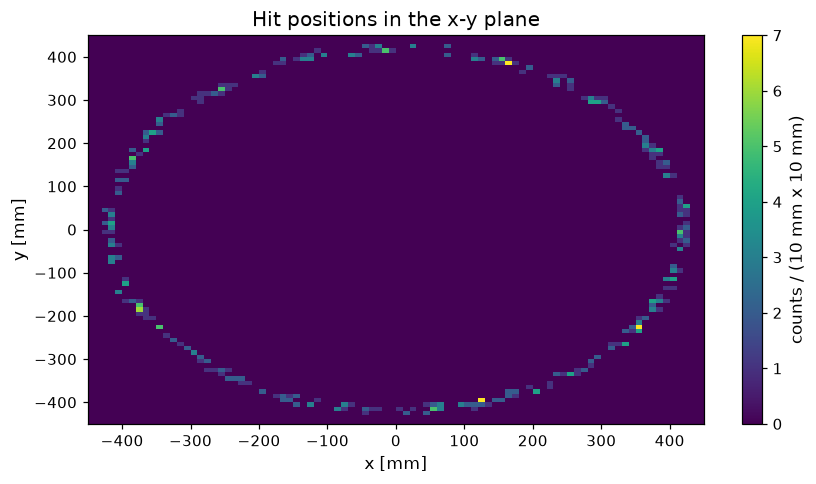

In [4]:
plotting.plot_hist_2d(
    x=frame["posX"],
    y=frame["posY"],
    xrange=(-450, 450),
    xbins=90,
    yrange=(-450, 450),
    ybins=90,
    xtitle="x [mm]",
    ytitle="y [mm]",
    title="Hit positions in the x-y plane",
    colorbar=True,
    colorbar_title="counts / (10 mm x 10 mm)",
)

How far from the axis, and how far along it, the hits lie — positions are in
millimetres, as GATE writes them:

In [5]:
import numpy as np

radius = np.sqrt(frame["posX"] ** 2 + frame["posY"] ** 2)
{
    "radius": (float(radius.min()), float(radius.max())),
    "z": (float(frame["posZ"].min()), float(frame["posZ"].max())),
}

{'radius': (410.1744079589844, 430.4044494628906),
 'z': (-529.1993408203125, 518.4874877929688)}

Every hit lies between 410.2 and 430.4 mm from the axis, and within about
530 mm of the middle along it: a ring of crystals some 20 mm deep, about a
metre long. The local positions say how big one crystal is, since every hit
lies inside the crystal it happened in:

In [6]:
{
    column: (float(frame[column].min()), float(frame[column].max()))
    for column in ("localPosX", "localPosY", "localPosZ")
}

{'localPosX': (-1.5940146446228027, 1.598942518234253),
 'localPosY': (-9.965958595275879, 9.965054512023926),
 'localPosZ': (-1.599640965461731, 1.5960612297058105)}

About ±1.6 mm across, ±10 mm along `y`: the crystals are 3.2 × 20 × 3.2 mm,
and the 20 mm side is the depth of the ring. Local `y` follows the distance
from the axis almost exactly, so the `y` axis of a crystal points outwards:

In [7]:
float(np.corrcoef(radius, frame["localPosY"])[0, 1])

0.9973724448283159

### A Ring

`in_cylinder` takes the point where its axis crosses the `x`-`y` plane, an
outer radius, and an inner radius that turns it into a ring. A ring from 409 to
500 mm holds the whole scanner, and so every hit:

In [8]:
len(frame.gate.in_cylinder((0, 0), radius=500.0, inner_radius=409.0))

500

### Surfaces Belong To The Shape

A hit sitting exactly on a surface counts as inside. A ring whose radii are
the distances of the nearest and the farthest hit keeps both of them; bring
the outer radius in by a micrometre and the farthest hit is outside:

In [9]:
nearest, farthest = float(radius.min()), float(radius.max())

(
    len(frame.gate.in_cylinder((0, 0), radius=farthest, inner_radius=nearest)),
    len(frame.gate.in_cylinder((0, 0), radius=farthest - 0.001, inner_radius=nearest)),
)

(500, 499)

The other convention would drop hits on a boundary, and a simulation puts
them there: the surface of a crystal is where a gamma enters it.

### A Layer Of The Ring

The ring split at 420 mm, into a front half nearer the axis and a back half
farther from it. The masks are counted rather than the rows cut, so that the
two halves can be compared:

In [10]:
front_ring = frame.gate.is_in_cylinder((0, 0), radius=420.0, inner_radius=410.0)
back_ring = frame.gate.is_in_cylinder((0, 0), radius=431.0, inner_radius=420.0)

int(front_ring.sum()), int(back_ring.sum()), int((front_ring & back_ring).sum())

(326, 174, 0)

Two hits in three stop in the front half: a gamma that has crossed 10 mm of
crystal has had its chance to interact. Both rings hold the surface at 420 mm,
so a hit lying exactly on it would be counted in each; none does here.

### The Ends Of The Cylinder

`z_range` gives the ends of the cylinder along its axis, which is unbounded
when it is left out. The two halves of the scanner along `z`:

In [11]:
(
    int(frame.gate.is_in_cylinder((0, 0), 500.0, z_range=(-530.0, 0.0), inner_radius=409.0).sum()),
    int(frame.gate.is_in_cylinder((0, 0), 500.0, z_range=(0.0, 530.0), inner_radius=409.0).sum()),
)

(248, 252)

### Another Axis

The cylinder runs along the **third** of the columns it reads, so another axis
is a matter of naming the columns in another order. A cylinder of radius
100 mm along `x` keeps the hits near that axis — the ones in the part of the
ring the `x` axis passes through:

In [12]:
along_x = frame.gate.in_cylinder((0, 0), 100.0, columns=("posY", "posZ", "posX"))
len(along_x), float(along_x["posX"].abs().min())

(26, 402.11065673828125)

### The Same Question In The Frame Of A Crystal

A box is described by its centre and the lengths of its sides, each reaching
half its length either way, as in a GATE macro. A box of 3.2 × 20 × 3.2 mm at
the origin is one crystal — in local coordinates it holds every hit, and in
the coordinates of the world it holds none, because nothing at the centre of
the scanner was hit:

In [13]:
LOCAL = ("localPosX", "localPosY", "localPosZ")
crystal = (3.2, 20.0, 3.2)

(
    int(frame.gate.is_in_box((0, 0, 0), crystal, columns=LOCAL).sum()),
    int(frame.gate.is_in_box((0, 0, 0), crystal).sum()),
)

(500, 0)

The front half of every crystal, asked in local coordinates — the half of
the box with negative `y`, which points towards the axis:

In [14]:
front_crystal = frame.gate.is_in_box((0, -5.0, 0), (3.2, 10.0, 3.2), columns=LOCAL)
int(front_crystal.sum())

336

The front half of the ring held 326 hits, the front half of the crystals
holds 336. Every hit of the ring's front half is in the crystals' front half
too; the difference is hits the ring puts at the back:

In [15]:
int((front_ring & ~front_crystal).sum()), int((front_crystal & ~front_ring).sum())

(0, 10)

A ring measures the distance from the axis, and the crystals are not set on a
circle: the crystals of one sector of the scanner sit side by side in a flat
block. A hit near the edge of its block sits farther from the axis than its
depth in the crystal says, so the ring reads it as deeper than it is.
The depth of interaction is a question about the crystal, and the local
coordinates answer it exactly.

### Where The Gammas Were Born

The third position, `sourcePos`, is read by naming its columns. A sphere of
1 mm around the centre holds every gamma's place of birth: the source of this
scene sat at the origin.

In [16]:
SOURCE = ("sourcePosX", "sourcePosY", "sourcePosZ")
len(frame.gate.in_sphere((0, 0, 0), 1.0, columns=SOURCE))

500

### What A Shape Refuses

A ring whose inner radius exceeds its outer one could hold nothing, and reads
more like two arguments swapped than like a question; a centre needs one value
per column it is centred in. Both are refused:

In [17]:
for call in (
    lambda: frame.gate.in_cylinder((0, 0), radius=409.0, inner_radius=500.0),
    lambda: frame.gate.in_sphere((0, 0), 500.0),
):
    try:
        call()
    except ValueError as error:
        print(error)

The inner radius of a ring cannot exceed its outer radius, got 500.0 and 409.0.
'centre' needs one value per column: 3 expected, 2 given.


## Summary

A box, a sphere and a cylinder — a ring, with an inner radius — select hits by
where they lie, in the numbers a GATE macro uses, with surfaces counted as
inside. A shape reads `pos` unless it is given other columns: `localPos` asks
the question in the frame of a crystal, which is where the depth of
interaction is measured exactly, and `sourcePos` asks it about where the
gammas were born.

## Bibliography

- [Filtering And Selecting](https://opengate-gate-tree.readthedocs.io/en/latest/guide/filtering.html)
  — the shapes, which columns they read, and why surfaces belong to them
- [The "Hits" Tree](https://opengate-gate-tree.readthedocs.io/en/latest/guide/hits.html)
  — the structure with a system, and the identifier branches of
  `cylindricalPET`
- [Units](https://opengate-gate-tree.readthedocs.io/en/latest/guide/units.html)
  — why positions are in millimetres
- [`tools/README.md`](tools/README.md) — the plotting helper used here

## Changelog

- v1: written.